In [6]:
import os
import sys
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../evaluation'))

import baseline
import load_smart_tagging
import possession_metrics as pm
import games
from kloppy import metrica

print("1. Loading raw data...")
raw_codes = baseline.build() # The naive nearest-player labels
events = load_smart_tagging.load()

paths = games.asset_paths(source='tactical')
dataset = metrica.load_tracking_epts(meta_data=paths['atd_meta'], raw_data=paths['atd_raw'])
df = dataset.to_df()

print("2. Extracting Smart Tags and Centers of Mass...")
dead_ball_frames = set()
for event in events:
    if event["code"].upper() == "SET PIECES":
        for frame in range(event["start_frame"], event["end_frame"]):
            dead_ball_frames.add(frame)

# Calculate Center of Mass (CoM)
home_cols_x = [c for c in df.columns if 'Home' in c and c.endswith('_x')]
home_cols_y = [c for c in df.columns if 'Home' in c and c.endswith('_y')]
away_cols_x = [c for c in df.columns if 'Away' in c and c.endswith('_x')]
away_cols_y = [c for c in df.columns if 'Away' in c and c.endswith('_y')]

df['home_com_x'] = df[home_cols_x].mean(axis=1)
df['home_com_y'] = df[home_cols_y].mean(axis=1)
df['away_com_x'] = df[away_cols_x].mean(axis=1)
df['away_com_y'] = df[away_cols_y].mean(axis=1)

# Forward and backward fill the ball to always have a reference point
df['ball_x_ffill'] = df['ball_x'].ffill().bfill()
df['ball_y_ffill'] = df['ball_y'].ffill().bfill()

# Distance arrays
home_dist = np.sqrt((df['home_com_x'] - df['ball_x_ffill'])**2 + (df['home_com_y'] - df['ball_y_ffill'])**2).values
away_dist = np.sqrt((df['away_com_x'] - df['ball_x_ffill'])**2 + (df['away_com_y'] - df['ball_y_ffill'])**2).values

print("3. Building improved frame-by-frame predictions...")
improved_codes = np.copy(raw_codes)

for t in range(len(raw_codes)):
    # Override 1: If it's a known stoppage, mark as Dead Ball (-1)
    if t in dead_ball_frames:
        improved_codes[t] = -1 
        
    # Override 2: If the ball is missing, use Center of Mass
    elif raw_codes[t] == -1: 
        if home_dist[t] < away_dist[t]:
            improved_codes[t] = 0 # Home
        elif away_dist[t] < home_dist[t]:
            improved_codes[t] = 1 # Away

print("4. Applying rolling window smoothing (window=50)...")
# baseline.smooth automatically handles the conversion to 'H', 'A', 'D' strings
final_labels = baseline.smooth(improved_codes, window=50)

print("5. Saving and Scoring...")
output_path = '../evaluation/results/my_hybrid_submission.csv'
baseline.write_submission(output_path, final_labels)

print("\n--- FINAL SCORING ---")
gt = pm.label_codes(pm.read_label_csv('../evaluation/gt/BAR-ATH_possession_gt_public.csv'))
results = pm.evaluate(gt, pm.label_codes(final_labels))

print(f"macroF1: {round(results['macro_f1'], 4)}")
print(f"spellF1: {round(results['spell_f1_mean'], 4)}")
print(f"Total Possessions: {results['n_pred_spells']}")

1. Loading raw data...
teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)

2. Extracting Smart Tags and Centers of Mass...
3. Building improved frame-by-frame predictions...
4. Applying rolling window smoothing (window=50)...
5. Saving and Scoring...

--- FINAL SCORING ---
macroF1: 0.6671
spellF1: 0.24
Total Possessions: 28


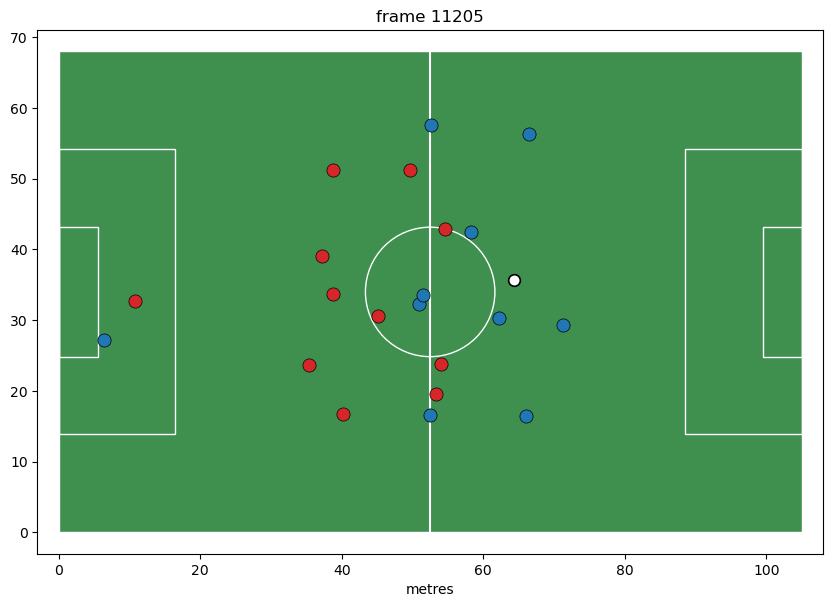

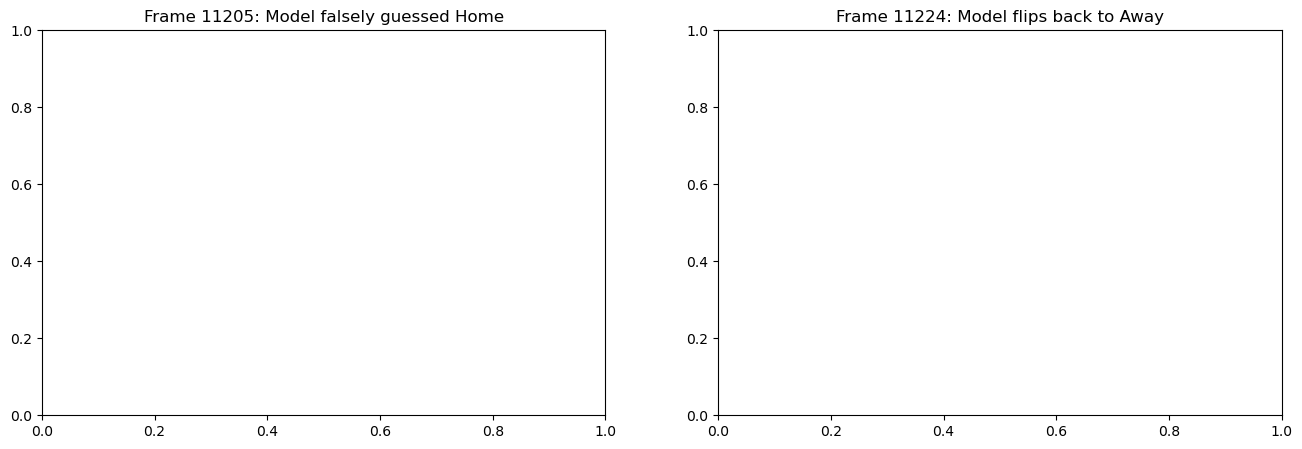

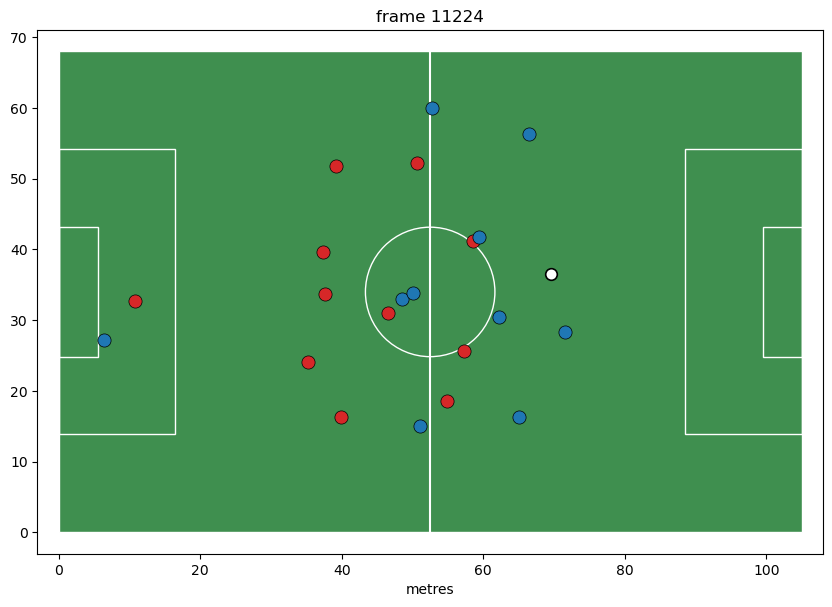

In [7]:
from starter import utils
import matplotlib.pyplot as plt

# The exact frame of the first spurious transition (A -> H)
frame_start = 11205
# The frame where it flipped back (H -> A)
frame_end = 11224

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot the start of the hallucinated possession
plt.sca(axes[0])
utils.plot_frame(dataset, frame_start)
axes[0].set_title(f"Frame {frame_start}: Model falsely guessed Home")

# Plot the end of the hallucinated possession
plt.sca(axes[1])
utils.plot_frame(dataset, frame_end)
axes[1].set_title(f"Frame {frame_end}: Model flips back to Away")

plt.show()

In [9]:
import os
import sys
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../evaluation'))

import baseline
import load_smart_tagging
import possession_metrics as pm
import games
from kloppy import metrica

print("1. Loading raw data...")
raw_codes = baseline.build() 
events = load_smart_tagging.load()

paths = games.asset_paths(source='tactical')
dataset = metrica.load_tracking_epts(meta_data=paths['atd_meta'], raw_data=paths['atd_raw'])
df = dataset.to_df()

print("2. Extracting Smart Tags and Centers of Mass (excluding Goalkeepers)...")
dead_ball_frames = set()
for event in events:
    if event["code"].upper() == "SET PIECES":
        for frame in range(event["start_frame"], event["end_frame"]):
            dead_ball_frames.add(frame)

df['ball_x_ffill'] = df['ball_x'].ffill().bfill()
df['ball_y_ffill'] = df['ball_y'].ffill().bfill()

home_cols_x = [c for c in df.columns if 'Home' in c and c.endswith('_x')]
home_cols_y = [c for c in df.columns if 'Home' in c and c.endswith('_y')]
away_cols_x = [c for c in df.columns if 'Away' in c and c.endswith('_x')]
away_cols_y = [c for c in df.columns if 'Away' in c and c.endswith('_y')]

home_com_x_arr = np.zeros(len(df))
home_com_y_arr = np.zeros(len(df))
away_com_x_arr = np.zeros(len(df))
away_com_y_arr = np.zeros(len(df))

for i in range(len(df)):
    bx = df.loc[i, 'ball_x_ffill']
    by = df.loc[i, 'ball_y_ffill']
    
    # HOME TEAM - Top 5 closest players
    hx = df.loc[i, home_cols_x].values.astype(float)
    hy = df.loc[i, home_cols_y].values.astype(float)
    h_dists = np.sqrt((hx - bx)**2 + (hy - by)**2)
    
    valid_h = ~np.isnan(h_dists)
    if valid_h.sum() > 0:
        h_dists_valid = h_dists[valid_h]
        hx_valid = hx[valid_h]
        hy_valid = hy[valid_h]
        
        closest_h_idx = np.argsort(h_dists_valid)[:min(5, len(h_dists_valid))]
        home_com_x_arr[i] = np.mean(hx_valid[closest_h_idx])
        home_com_y_arr[i] = np.mean(hy_valid[closest_h_idx])
    else:
        home_com_x_arr[i] = np.nan
        home_com_y_arr[i] = np.nan

    # AWAY TEAM - Top 5 closest players
    ax = df.loc[i, away_cols_x].values.astype(float)
    ay = df.loc[i, away_cols_y].values.astype(float)
    a_dists = np.sqrt((ax - bx)**2 + (ay - by)**2)
    
    valid_a = ~np.isnan(a_dists)
    if valid_a.sum() > 0:
        a_dists_valid = a_dists[valid_a]
        ax_valid = ax[valid_a]
        ay_valid = ay[valid_a]
        
        closest_a_idx = np.argsort(a_dists_valid)[:min(5, len(a_dists_valid))]
        away_com_x_arr[i] = np.mean(ax_valid[closest_a_idx])
        away_com_y_arr[i] = np.mean(ay_valid[closest_a_idx])
    else:
        away_com_x_arr[i] = np.nan
        away_com_y_arr[i] = np.nan

home_dist = np.sqrt((home_com_x_arr - df['ball_x_ffill'].values)**2 + (home_com_y_arr - df['ball_y_ffill'].values)**2)
away_dist = np.sqrt((away_com_x_arr - df['ball_x_ffill'].values)**2 + (away_com_y_arr - df['ball_y_ffill'].values)**2)

print("3. Building improved frame-by-frame predictions...")
improved_codes = np.copy(raw_codes)

for t in range(len(raw_codes)):
    if t in dead_ball_frames:
        improved_codes[t] = -1 
    elif raw_codes[t] == -1: 
        if home_dist[t] < away_dist[t]:
            improved_codes[t] = 0 
        elif away_dist[t] < home_dist[t]:
            improved_codes[t] = 1 

print("4. Applying rolling window smoothing (window=125)...")
final_labels = baseline.smooth(improved_codes, window=125)
final_labels = np.array(final_labels) # Convert to numpy array for easier manipulation

print("4b. Applying Short Spell Eraser...")
min_spell_frames = 25
current_team = final_labels[0]
spell_start = 0

for t in range(1, len(final_labels)):
    if final_labels[t] != current_team:
        spell_length = t - spell_start
        
        # If the spell was too short, overwrite it with the previous team's possession
        if spell_length < min_spell_frames and spell_start > 0:
            previous_team = final_labels[spell_start - 1]
            final_labels[spell_start:t] = previous_team
            
        current_team = final_labels[t]
        spell_start = t

print("5. Saving and Scoring...")
output_path = '../evaluation/results/my_hybrid_submission.csv'
baseline.write_submission(output_path, final_labels.tolist())

print("\n--- FINAL SCORING ---")
gt = pm.label_codes(pm.read_label_csv('../evaluation/gt/BAR-ATH_possession_gt_public.csv'))
results = pm.evaluate(gt, pm.label_codes(final_labels.tolist()))

print(f"macroF1: {round(results['macro_f1'], 4)}")
print(f"spellF1: {round(results['spell_f1_mean'], 4)}")
print(f"Total Possessions: {results['n_pred_spells']}")

1. Loading raw data...
teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)

2. Extracting Smart Tags and Centers of Mass (excluding Goalkeepers)...
3. Building improved frame-by-frame predictions...
4. Applying rolling window smoothing (window=125)...
4b. Applying Short Spell Eraser...
5. Saving and Scoring...

--- FINAL SCORING ---
macroF1: 0.6871
spellF1: 0.4
Total Possessions: 14


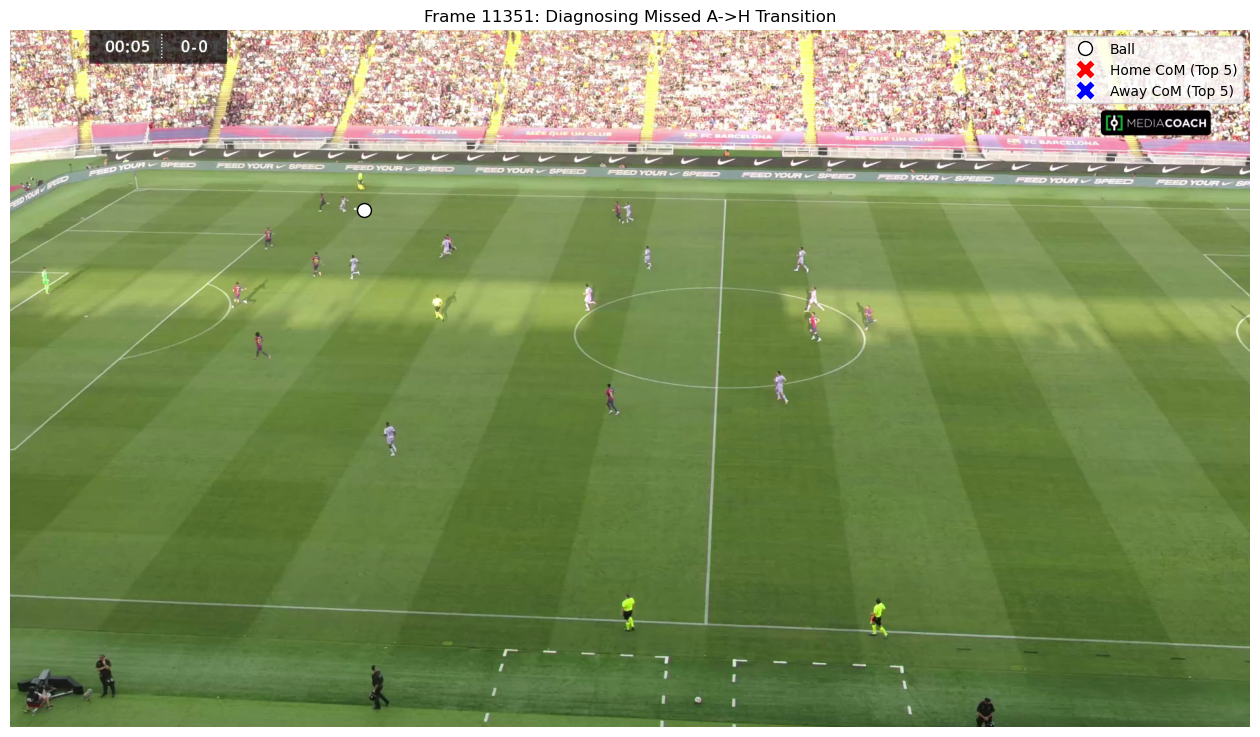

In [12]:
import cv2
import matplotlib.pyplot as plt
import load_homography

# Target a missed transition from the report
frame_idx = 11351

# 1. Load the homography matrices
matrices, reproj_err, valid = load_homography.load(source='tactical')
H = matrices[frame_idx]

# 2. Extract the exact frame from the MP4 video
video_path = '../data/tactical/BAR-ATH_tactical.mp4'
cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
ret, frame_img = cap.read()

# Convert color from BGR to RGB for matplotlib
frame_img = cv2.cvtColor(frame_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 10))
plt.imshow(frame_img)

# 3. Project all Home players (Red) onto the video
for col_x, col_y in zip(home_cols_x, home_cols_y):
    if not np.isnan(df.loc[frame_idx, col_x]):
        px, py = load_homography.project(H, df.loc[frame_idx, col_x], df.loc[frame_idx, col_y])
        plt.plot(px, py, 'ro', markersize=6, alpha=0.5)

# 4. Project all Away players (Blue) onto the video
for col_x, col_y in zip(away_cols_x, away_cols_y):
    if not np.isnan(df.loc[frame_idx, col_x]):
        px, py = load_homography.project(H, df.loc[frame_idx, col_x], df.loc[frame_idx, col_y])
        plt.plot(px, py, 'bo', markersize=6, alpha=0.5)

# 5. Project the Ball
bx, by = df.loc[frame_idx, 'ball_x_ffill'], df.loc[frame_idx, 'ball_y_ffill']
px, py = load_homography.project(H, bx, by)
plt.plot(px, py, 'wo', markersize=10, markeredgecolor='black', label="Ball")

# 6. Project the Localized Centers of Mass
hx, hy = home_com_x_arr[frame_idx], home_com_y_arr[frame_idx]
hpx, hpy = load_homography.project(H, hx, hy)
plt.plot(hpx, hpy, 'rX', markersize=15, markeredgecolor='white', label="Home CoM (Top 5)")

ax, ay = away_com_x_arr[frame_idx], away_com_y_arr[frame_idx]
apx, apy = load_homography.project(H, ax, ay)
plt.plot(apx, apy, 'bX', markersize=15, markeredgecolor='white', label="Away CoM (Top 5)")

plt.title(f"Frame {frame_idx}: Diagnosing Missed A->H Transition")
plt.legend(loc="upper right")
plt.axis('off')
plt.show()